# Inversión gravimétrica–magnética M11: matriz física de controles

**Pregunta:** En los 24 controles M11, ¿cómo varían el acoplamiento seleccionado y las fallas retenidas por familia?
**Nivel 3 — Análisis de flujo físico**  
**Requisitos previos:** notebooks conjuntos 1–3, mínimos cuadrados ponderados y regularización cross-gradient; 45 min.

## Objetivos

Inspeccionar ejecuciones reales del solver para controles gravimétricos y magnéticos; reconstruir el resumen de convergencia y acoplamiento por caso; distinguir convergencia, selección retenida, elegibilidad de campo y activación de publicación.

## Preparación

Lee el recibo de precisión M11 comprometido; no se vuelve a ejecutar el solver ni se escriben archivos. Versiones exactas: `numpy==2.2.6`, `matplotlib==3.10.8`.

```bash
python -m pip install numpy==2.2.6 matplotlib==3.10.8
```

## Datos

El recibo revisado de M11 resume 24 controles ejecutables de gravedad y magnetismo: casos coestructurales, disjuntos, planos/nulos y de campo incorrecto, con geometrías densas, bloqueadas dispersas y desplazadas, y covarianza diagonal o completa. Registra por caso el número de candidatos, acoplamiento seleccionado, finalización del flujo y replay. Todos los modelos y datos de control son sintéticos.

## Método

El objetivo físico es F = f_d,g + f_d,m + beta_g R_g + beta_m R_m + lambda C. Los términos de datos de gravedad y magnetismo se ponderan e informan por separado; cada modalidad tiene su propia línea base optimizada independientemente. C es el término CrossGradient de SimPEG en celdas activas, con la malla y máscaras declaradas. La selección de lambda usa validación y está limitada por la línea base de cada modalidad. Los candidatos no convergidos permanecen en el recibo: no se eliminan ni cuentan como soluciones.

## Comparación

La inversión conjunta con acoplamiento cross-gradient es un método estructural establecido. El tutorial oficial de SimPEG muestra otro ejemplo escalar y no valida las unidades, máscaras, covarianza, optimizador ni reglas de aceptación físicas de este repositorio. Esta lección lee el recibo del solver del proyecto, no los resultados del tutorial. Una matriz sintética de 24 casos es un estudio controlado de ingeniería, no evidencia geológica de campo ni beneficio universal del acoplamiento.

### Leer la matriz como experimento de método inverso

La inversión conjunta busca un modelo que explique varios datos físicos balanceando sensibilidades y ruidos diferentes. El acoplamiento estructural relaciona gradientes de propiedades; no funde la física gravimétrica y magnética en una ecuación directa. Este recibo evalúa respuestas por modalidad con metadatos de fuente, covarianza, geometría y prior propios. La matriz varía familia estructural, régimen de adquisición y covarianza para separar esos factores en diseño sintético controlado.

Los 24 flujos no son 24 encuestas de campo independientes. Son controles diseñados: familias coestructural, disjunta, plana/nula y campo incorrecto cruzadas con geometría densa, bloqueada/escasa y desplazada, además de covarianza diagonal o completa. Exponen modos de falla. Acoplamientos elegidos son resultados de validación dentro del diseño, no un óptimo transferible. Selección positiva en cada caso no prueba mejora predictiva retenida; depende de candidatos, escalado, partición y presupuesto.

Convergencia es solo una parte. Un optimizador convergente puede caer en mínimo local pobre, ajustar ruido o ser no identificable. La no convergencia debe conservarse: eliminarla exageraría fiabilidad. El recibo contiene 524 solves candidatos convergentes y 100 no convergentes. Flujos completados y reproducidos no significan que cada optimización convergió.

La validación replay reconstruye entradas, selección, predicciones y métricas bajo contrato numérico. Mejora trazabilidad, pero no crea evidencia independiente: confirma cadena computacional sintética, no verdad geológica. El caso de máximo conteo mide memoria del host para una forma y covarianza; no garantiza otra máquina ni autoriza consumo ilimitado. Factibilidad de recursos, precisión, aceptación científica y despliegue son puertas distintas.

Elegibilidad de campo es falsa: faltan entradas medidas con derechos, validación representativa externa, incertidumbre robusta y corroboración geológica independiente. Predicados de controles de cara exacta pueden pasar mientras aceptación global sigue falsa; son verificaciones necesarias, no permiso de activación. El diagrama de cajas resume valores entre 24 selecciones. Fallas, recibo de recursos y banderas negativas son parte del resultado científico.

### Límite de aceptación e interpretación

La aceptación científica pregunta si la evidencia respalda un uso definido, no solo si una ruta ejecutable devolvió un número. El recibo separa flujo completado, replay, predicados de precisión, elegibilidad de campo, aceptación y activación pública. Deben leerse por separado. La prueba de recursos con covarianza completa puede pasar asignación y replay mientras activación de campo sigue falsa. Conteos de predicados de cara exacta describen controles numéricos, no confianza poblacional ni probabilidad de corrección geológica.

La matriz es útil porque incluye controles adversariales: estructuras disjuntas y campo magnético incorrecto prueban si se selecciona acoplamiento cuando falla la hipótesis compartida. Casos planos/nulos prueban soporte débil de gradiente y geometría desplazada prueba desajuste de adquisición. Retenerlos convierte la matriz en herramienta de falsación. Resumir solo familia coestructural ocultaría precisamente condiciones donde un prior produce límites compartidos plausibles pero no sustentados.

## Resultados

**Respuesta:** El recibo contiene 24 flujos completados y validados por reproducción; conserva 524 candidatos convergentes y 100 no convergentes. Se eligió acoplamiento positivo en 24/24 controles; elegibilidad de campo y activación pública siguen falsas.

## Resumen

La matriz permite un análisis acotado de recursos y selección sintéticos. Las fallas retenidas y banderas falsas impiden leer estos resultados como aceptación de campo o conclusión física universal.

## Referencias

1. Tutorial de inversión conjunta CrossGradient de SimPEG: https://docs.simpeg.xyz/latest/content/user-guide/tutorials/13_joint_inversion/plot_inv_3_cross_gradient_pf.html.
2. Cockett et al. (2015), SimPEG: An open source framework for simulation and gradient based parameter estimation in geophysical applications, https://doi.org/10.1016/j.cageo.2015.09.015.
3. Métodos y evidencia del repositorio: docs/design/features/joint-survey-inversion/algorithms.md y docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json.


### Experimento 1 — Verificar fuente y los 24 flujos

In [1]:
# Localice y calcule el hash del recibo inmutable M11 antes de interpretar sus registros.
from pathlib import Path
from importlib.metadata import version
import hashlib
import json
import numpy as np
import matplotlib.pyplot as plt

root = next(
    p
    for p in (Path.cwd(), *Path.cwd().parents)
    if (p / "docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json").is_file()
)
receipt_path = root / "docs/design/features/joint-survey-inversion/evidence/m11-final-precision-20261025.json"
raw = receipt_path.read_bytes()
receipt_sha256 = hashlib.sha256(raw).hexdigest()
assert (
    receipt_sha256 == "94b6adee9a62e41eb57783446aaaf2c48b92bda4ef4bc11a97429b861c75cd1a"
), "M11 receipt hash changed"
print("Entorno de ejecución:", {name: version(name) for name in ("numpy", "matplotlib")})
print("SHA-256 fijado del recibo:", receipt_sha256)


Entorno de ejecución: {'numpy': '2.2.6', 'matplotlib': '3.10.8'}
SHA-256 fijado del recibo: 94b6adee9a62e41eb57783446aaaf2c48b92bda4ef4bc11a97429b861c75cd1a


### Verificar la ejecución y su reproducción

Después de comprobar la identidad de los bytes, lea el esquema y cuente todos los flujos completados. La validación por reproducción es una propiedad de las ejecuciones registradas; no implica elegibilidad de campo ni aceptación científica para publicación.

In [2]:
# Valide el esquema del registro, el conteo completo de flujos y el estado de reproducción.
r = json.loads(raw)
assert r["schema"] == "caos-geophysics.m11-final-precision-receipt/v1"
records = r["matrix"]["summary"]["records"]
assert len(records) == 24 and all(
    x["workflow_status"] == "completed" and x["replay_validated"] for x in records
)
print(
    "Casos / flujos / reproducción validada:",
    len(records),
    r["matrix"]["complete_cli_workflows"],
    sum(x["replay_validated"] for x in records),
)
print("Totales de estado de candidatos:", r["matrix"]["candidate_fits"])
print(
    "Elegible para campo / M11 aceptado / activación pública:",
    r["method_scope"]["field_eligible"],
    r["method_scope"]["full_m11_release_accepted"],
    r["method_scope"]["public_activation"],
)


Casos / flujos / reproducción validada: 24 24 24
Totales de estado de candidatos: {'converged': 524, 'failed': 0, 'nonconverged': 100, 'eligible_positive': 181}
Elegible para campo / M11 aceptado / activación pública: False False False


### Experimento 2 — Comparar acoplamiento y resultados del optimizador por caso

In [3]:
# Reconstruya la matriz de controles físicos a partir del recibo registrado por caso.
records = r["matrix"]["summary"]["records"]
family_order = ["co_structural", "disjoint", "flat_null", "wrong_field"]
regime_order = ["dense", "sparse_blocked", "shifted_geometry"]
columns = [(regime, cov) for regime in regime_order for cov in (False, True)]
coupling = np.full((len(family_order), len(columns)), np.nan)
for item in records:
    row = family_order.index(item["family"])
    col = columns.index((item["regime"], item["covariance"]))
    coupling[row, col] = item["selected_coupling"]
assert np.isfinite(coupling).all()


### Representar el acoplamiento y los resultados del solver

El primer panel muestra el acoplamiento seleccionado en escala logarítmica. El segundo conserva los conteos de candidatos convergentes y no convergentes para cada familia. Un valor seleccionado es un resultado del optimizador bajo esta matriz, no evidencia de que la inversión conjunta mejore una interpretación de campo.

In [4]:
# Resuma los resultados de candidatos sin descartar las resoluciones fallidas.
converged = []
nonconverged = []
for family in family_order:
    subset = [item for item in records if item["family"] == family]
    converged.append(sum(item["candidate_counts"]["converged"] for item in subset))
    nonconverged.append(sum(item["candidate_counts"]["nonconverged"] for item in subset))
positions = np.arange(len(family_order))


### Acoplamiento seleccionado por familia controlada

El mapa usa log10 del acoplamiento elegido en validación y mantiene separadas las seis combinaciones de adquisición y covarianza. Las diferencias entre filas muestran que la regularización depende de la estructura física y de la geometría del levantamiento. La selección por sí sola no demuestra beneficio predictivo ni identifica un modelo único del subsuelo.

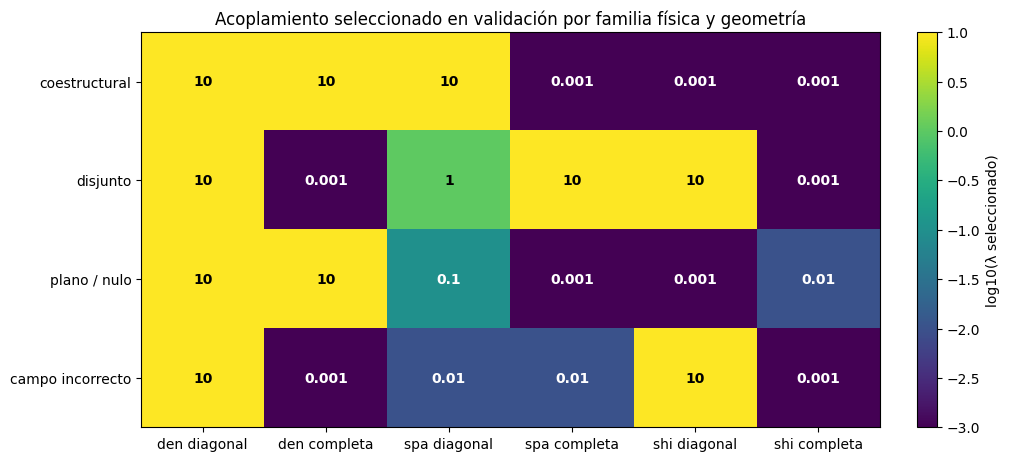

In [5]:
# Muestre el acoplamiento seleccionado para cada familia, régimen y elección de covarianza.
fig, ax = plt.subplots(figsize=(10, 4.5), constrained_layout=True)
image = ax.imshow(np.log10(coupling), aspect="auto", cmap="viridis", vmin=-3, vmax=1)
ax.set(yticks=np.arange(4), yticklabels=["coestructural", "disjunto", "plano / nulo", "campo incorrecto"])
labels = [f"{regime[:3]} {'completa' if cov else 'diagonal'}" for regime, cov in columns]
ax.set(xticks=np.arange(6), xticklabels=labels)
ax.set_title("Acoplamiento seleccionado en validación por familia física y geometría")
for i in range(coupling.shape[0]):
    for j in range(coupling.shape[1]):
        value = coupling[i, j]
        color = "white" if np.log10(value) < -0.2 else "black"
        ax.text(j, i, f"{value:g}", ha="center", va="center", color=color, fontweight="bold")
fig.colorbar(image, ax=ax, label="log10(λ seleccionado)")
plt.show()


### Resultados del solver por familia controlada

Las barras apiladas conservan las soluciones candidatas convergentes y no convergentes de las cuatro familias. Un número alto de convergencias no garantiza un modelo científicamente aceptable, y omitir fallas exageraría el resultado computacional. Interprete estos conteos junto con el panel de acoplamiento y el límite explícito de elegibilidad de campo.

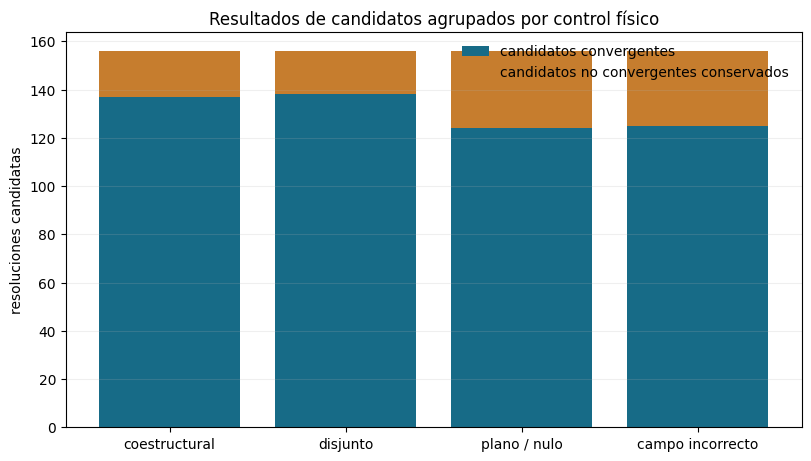

Acoplamiento positivo seleccionado: 24 de 24


In [6]:
# Mantenga visibles todos los candidatos convergentes y no convergentes en los totales por familia.
fig, ax = plt.subplots(figsize=(8, 4.5), constrained_layout=True)
ax.bar(positions, converged, color="#176b87", label="candidatos convergentes")
ax.bar(positions, nonconverged, bottom=converged, color="#c67d2e", label="candidatos no convergentes conservados")
ax.set(xticks=positions, xticklabels=["coestructural", "disjunto", "plano / nulo", "campo incorrecto"])
ax.set_ylabel("resoluciones candidatas")
ax.set_title("Resultados de candidatos agrupados por control físico")
ax.grid(axis="y", alpha=0.2)
ax.legend(frameon=False)
plt.show()
print(
    "Acoplamiento positivo seleccionado:", r["matrix"]["positive_coupling_selected_cases"], "de", r["matrix"]['cases']
)


### Dispersión del acoplamiento por familia
Cada caja resume seis acoplamientos seleccionados por validación para una familia declarada, entre tres regímenes de adquisición y opciones de covarianza. La dispersión es un diagnóstico de selección del optimizador dentro de esta matriz sintética fija, no incertidumbre geológica. Se conservan las fallas de convergencia y la inelegibilidad de campo registradas.

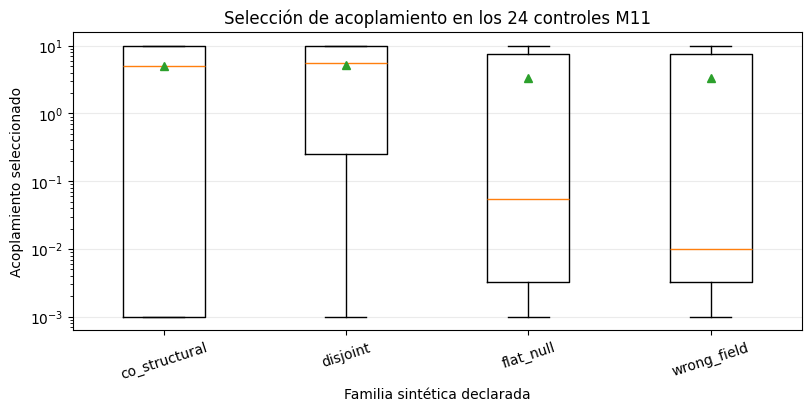

In [7]:
# Grafique los acoplamientos seleccionados por validación para las cuatro familias de control físico.
family_order = ["co_structural", "disjoint", "flat_null", "wrong_field"]
family_values = [[x["selected_coupling"] for x in records if x["family"] == family] for family in family_order]
fig, ax = plt.subplots(figsize=(8, 4), constrained_layout=True)
ax.boxplot(family_values, tick_labels=family_order, showmeans=True)
ax.set_yscale("log")
ax.set(
    xlabel="Familia sintética declarada",
    ylabel="Acoplamiento seleccionado",
    title="Selección de acoplamiento en los 24 controles M11",
)
ax.tick_params(axis="x", rotation=18)
ax.grid(axis="y", alpha=0.25)
plt.show()


### Experimento 3 — Revisar límites de recursos y precisión

Los valores graficados se recalculan desde las entradas del notebook y usan las unidades indicadas en los ejes. La comparación muestra solo la métrica y partición declaradas; no establece un subsuelo único, precisión fuera de este proceso generador ni idoneidad operativa. Léala junto al control negativo retenido y las limitaciones anteriores.

In [8]:
# Mantenga la evidencia local de recursos separada de la elegibilidad de campo y la aceptación de publicación.
resource = r["maximum_count_resource_gate"]
precision = r["exact_face_precision"]
print("Flujo físico de conteo máximo:")
for key in (
    "full_cells",
    "active_cells",
    "receivers_per_modality",
    "full_covariance",
    "active_count_plus_one_rejected",
    "workflow_status",
    "workflow_peak_sampled_rss_bytes",
    "replay_validated",
    "field_eligible",
    "public_activation",
):
    print(f"  {key}: {resource[key]}")
print(
    "Controles de caras exactas:",
    precision["candidate_status_counts"],
    "predicados científicos aceptados:",
    precision["all_scientific_predicates_pass"],
)


Flujo físico de conteo máximo:
  full_cells: 4096
  active_cells: 1932
  receivers_per_modality: 2048
  full_covariance: True
  active_count_plus_one_rejected: True
  workflow_status: completed
  workflow_peak_sampled_rss_bytes: 494010368
  replay_validated: True
  field_eligible: False
  public_activation: False
Controles de caras exactas: {'converged': 343, 'nonconverged': 41} predicados científicos aceptados: True


### El recibo verificado aporta la matriz de acoplamientos seleccionados y los conteos de convergencia para cuatro familias físicas sintéticas. En los casos registrados se seleccionó un acoplamiento positivo, pero esto es un resultado de validación dentro del diseño evaluado. No establece elegibilidad de campo, un modelo terrestre único ni aceptación para publicación; el recibo mantiene explícitamente esas decisiones en falso.

In [9]:
# Conserve fallas candidatas para que el resumen no oculte inestabilidad del solver.
assert (
    resource["replay_validated"]
    and resource["field_eligible"] is False
    and resource["public_activation"] is False
)
assert r["matrix"]["summary"]["original_precision_failures_retained"] is True
print(
    "Interpretación: solo controles sintéticos locales. La no convergencia permanece visible; no se deriva ninguna afirmación de campo."
)


Interpretación: solo controles sintéticos locales. La no convergencia permanece visible; no se deriva ninguna afirmación de campo.


### Cálculo por cohorte

Este cálculo agrupa resultados verificados por familia de casos declarada. Los conteos conservan ejecuciones fallidas y no convergentes; no establecen elegibilidad de campo ni recuperación del optimizador.


In [10]:
# Recalcule los conteos de convergencia por familia a partir del recibo físico verificado.
from collections import Counter

status_by_family = {
    family: Counter(x["workflow_status"] for x in records if x["family"] == family)
    for family in sorted({x["family"] for x in records})
}
print("completados/no convergentes por familia", status_by_family)


completados/no convergentes por familia {'co_structural': Counter({'completed': 6}), 'disjoint': Counter({'completed': 6}), 'flat_null': Counter({'completed': 6}), 'wrong_field': Counter({'completed': 6})}


### Salida calculada del método

Calcula un estadístico de familia o cohorte pareada desde entradas verificadas; no ejecuta ni reajusta la inversión.


In [11]:
# Derive una tabla de contingencia a partir de todos los registros verificados del solver.
import pandas as pd

status_table = pd.crosstab([x["family"] for x in records], [x["workflow_status"] for x in records])
print(status_table.to_string())


col_0          completed
row_0                   
co_structural          6
disjoint               6
flat_null              6
wrong_field            6


### Salida calculada del método

Calcula un estadístico de familia o cohorte pareada desde entradas verificadas; no ejecuta ni reajusta la inversión.


In [12]:
# Recalcule el rango de acoplamiento seleccionado sin filtrar los flujos fallidos.
selected_values = np.asarray([x["selected_coupling"] for x in records], float)
print(
    "finitos",
    int(np.isfinite(selected_values).sum()),
    "rango",
    float(np.nanmin(selected_values)),
    float(np.nanmax(selected_values)),
)


finitos 24 rango 0.001 10.0


### Reconstruir un control físico con el motor directo

Seleccione uno de los controles fijos M11 y deje que el repositorio construya sus datos gravimétricos y magnéticos declarados. Esta llamada ejecuta la ruta de entrada científica; el recibo de 24 casos sigue describiendo la matriz amplia de optimización.


In [13]:
# Reconstruya un control sintético declarado con el motor directo fijado.
import sys

sys.path.insert(0, str(root / "data-pipeline"))
import joint_survey_cases

control = joint_survey_cases.make_joint_control(0)
print("caso", control["case_id"], control["family"], control["regime"])
print("modalidades", sorted(control["survey_request"].keys() & {"gravity", "magnetic"}))


caso joint-control-00 co_structural dense
modalidades ['gravity', 'magnetic']


### Admitir el plan del levantamiento

El planificador comprueba unidades, geometría receptora, particiones, covarianza, orden de malla y límites de recursos antes de evaluar el objetivo. El resumen debe coincidir con el digest calculado al construir el control, señal de que ambos pasos usaron la misma solicitud.


In [14]:
# Admita la misma solicitud de levantamiento mediante la API pública.
import joint_survey_plan

control_plan = joint_survey_plan.plan_joint_survey(control["survey_request"])
assert control_plan["plan_sha256"] == control["development"]["plan_sha256"]
print("celdas activas planificadas", control_plan["diagnostics"]["active_cells"])


celdas activas planificadas 12


### Compilar el problema inverso de desarrollo

La compilación vincula observaciones de desarrollo y su modelo de ruido con los operadores directos planificados. Las filas selladas no se entregan a este método y el objeto compilado no representa un resultado del optimizador. Usaremos el modelo inicial normalizado para comparar dos interfaces con entradas idénticas.


In [15]:
# Compile solo las observaciones de desarrollo y el contrato del levantamiento.
import joint_survey_compiled

problem = joint_survey_compiled.compile_joint_development(
    {
        "schema": "joint-survey-compile-request-1",
        "survey_request": control["survey_request"],
        "development": control["development"],
    }
)
q_control = problem.start.copy()
print("parámetros del modelo compilado", len(q_control), "hash", problem.development_sha256)


parámetros del modelo compilado 24 hash 56d8c70997a6e42e57b9533c7397e7b28f3fb7689c310b3119afd64ce429b2a4


### Evaluar el objetivo físico en el modelo inicial

La llamada calcula términos de residuo gravimétrico y magnético, regularización, acoplamiento de gradiente cruzado, gradiente y producto Hessiano-vectorial para el mismo control de 12 celdas. Evalúa un estado; no ejecuta el ajuste no lineal que resume el recibo.


In [16]:
# Evalúe el objetivo físico público en el modelo inicial compilado.
import joint_survey_objective

prior = control["survey_request"]["prior"]
objective_result = joint_survey_objective.evaluate_joint_objective(
    {
        "schema": "joint-survey-objective-request-1",
        "survey_request": control["survey_request"],
        "development": control["development"],
        "models": {
            "density_kg_m3": prior["density"]["start"],
            "susceptibility_si": prior["susceptibility"]["start"],
        },
        "direction_physical": np.zeros(24),
        "weights": {"beta_gravity": 0.0001, "beta_magnetic": 0.0001, "coupling": 0.0},
    }
)
print("objetivo", objective_result['objective'], "términos", objective_result["terms"])


objetivo 32.97655447858452 términos {'data_gravity': 18.89476419413715, 'regularization_gravity': 0.0, 'data_magnetic': 14.081790284447372, 'regularization_magnetic': 0.0, 'coupling': 0.0}


### Comparar dos rutas directas con los mismos receptores

La predicción del problema compilado y la API del objetivo evalúan el mismo modelo inicial y las mismas filas receptoras. Su coincidencia punto a punto es una verificación de implementación sobre datos compartidos; no describe geología recuperada ni convergencia del optimizador.


In [17]:
# Prediga mediante la referencia compilada y compare los arreglos del objetivo.
compiled_prediction = problem.predict(q_control)
parity = {}
for modality in ("gravity", "magnetic"):
    rows = objective_result["predictions"][modality]["rows"]
    api_values = objective_result["predictions"][modality]["predicted"]
    compiled_values = compiled_prediction[modality][rows]
    parity[modality] = float(np.max(np.abs(api_values - compiled_values)))
    assert np.allclose(api_values, compiled_values, rtol=1e-10, atol=1e-12)
print("diferencia absoluta máxima con misma entrada", parity)


diferencia absoluta máxima con misma entrada {'gravity': 0.0, 'magnetic': 4.440892098500626e-16}


### Figura de paridad directa en los mismos datos

Cada punto compara una predicción por receptor de la API del objetivo con la ruta compilada. La diagonal es la referencia numérica; gravedad y magnetismo conservan sus unidades y escalas. La concordancia corresponde solo a este control diseñado, modelo inicial y par de implementaciones.


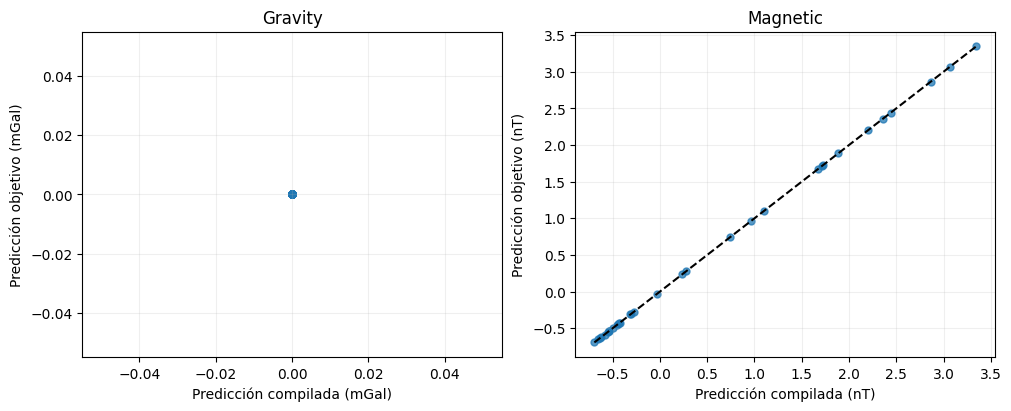

In [18]:
# Grafique las predicciones API frente a la referencia compilada por receptor.
fig, axes = plt.subplots(1, 2, figsize=(10, 4), constrained_layout=True)
for axis, modality, unit in zip(axes, ("gravity", "magnetic"), ("mGal", "nT")):
    rows = objective_result["predictions"][modality]["rows"]
    api_values = np.asarray(objective_result["predictions"][modality]["predicted"])
    reference_values = compiled_prediction[modality][rows]
    limits = [min(api_values.min(), reference_values.min()), max(api_values.max(), reference_values.max())]
    axis.scatter(reference_values, api_values, s=25, alpha=0.75)
    axis.plot(limits, limits, "k--")
    axis.set(xlabel=f"Predicción compilada ({unit})", ylabel=f"Predicción objetivo ({unit})", title=modality.title())
    axis.grid(alpha=0.2)
plt.show()


### Experimento 4 — Ejecute el optimizador real solo con datos de desarrollo

Vuelva a ejecutar la calibración del repositorio sobre el control denso coestructural admitido. Esto evalúa 16 candidatos beta independientes por modalidad y diez candidatos conjuntos desde dos estados iniciales permitidos. El solver solo recibe datos de desarrollo; no recibe la partición sellada ni la verdad. Cada candidato que no converge permanece en el registro. Los valores WRMS de validación se informan por modalidad; este único control sintético pequeño no demuestra un beneficio conjunto general ni validez de campo.

In [19]:
# Ejecute la calibración del producto y conserve fallos y límite medido del espacio temporal.
import contextlib
import io
import tempfile

import joint_survey_optimizer
import joint_survey_resources

with tempfile.TemporaryDirectory(prefix="m11-live-calibration-") as workspace:
    scratch = Path(workspace) / "scratch"
    scratch.mkdir()
    with joint_survey_resources.JointResourceBudget(str(scratch)) as resource_budget:
        with contextlib.redirect_stdout(io.StringIO()):
            live_m11 = joint_survey_optimizer.calibrate_joint_development(problem, resource_budget)

assert len(live_m11["candidates"]) == 26
assert live_m11["selection"] is not None
print("calibración nueva", live_m11["status"], live_m11["reason"])
print("candidatos reales", len(live_m11["candidates"]))
print("convergentes / no convergentes", {
    status: sum(c["result"]["status"] == status for c in live_m11["candidates"])
    for status in ("converged", "nonconverged")
})
for modality in ("gravity", "magnetic"):
    baseline = live_m11["selection"]["baseline_validation_wrms"][modality]
    selected = live_m11["selection"]["validation_wrms"][modality]
    print(modality, {
        "wrms_validacion_referencia_optimizada_por_separado": baseline,
        "wrms_validacion_seleccion_conjunta": selected,
        "cambio": selected - baseline,
    })
trace_stage = live_m11["selection"]["stage"]
if trace_stage is None:
    trace_stage = live_m11["selected_baselines"]["gravity"]
trace_candidate = next(c for c in live_m11["candidates"] if c["stage"] == trace_stage)
trace_terms = np.asarray(trace_candidate["terms_trace"])
assert trace_terms.ndim == 2 and trace_terms.shape[1] == 5
print("trayectoria mostrada", trace_candidate["result"]["status"], trace_candidate["weights"], trace_candidate["start_kind"])


calibración nueva selected validated_coupled_selection
candidatos reales 26
convergentes / no convergentes {'converged': 22, 'nonconverged': 4}
gravity {'wrms_validacion_referencia_optimizada_por_separado': 0.8126869896857115, 'wrms_validacion_seleccion_conjunta': 0.8126863543340618, 'cambio': -6.353516497359379e-07}
magnetic {'wrms_validacion_referencia_optimizada_por_separado': 1.3125754119848994, 'wrms_validacion_seleccion_conjunta': 1.3125743949665214, 'cambio': -1.0170183779578679e-06}
trayectoria mostrada converged {'beta_gravity': 100.0, 'beta_magnetic': 1000.0, 'coupling': 10.0} submitted


### Lea la trayectoria y el efecto por modalidad

El panel izquierdo descompone la trayectoria aceptada en los dos términos de datos, las dos regularizaciones ponderadas y la penalización de gradiente cruzado. El panel derecho compara el WRMS de validación con cada referencia optimizada por separado. Un cambio casi nulo se informa como tal; no se presenta como una mejora relevante. La trayectoria es un diagnóstico numérico, no un intervalo de confianza ni una predicción de campo.


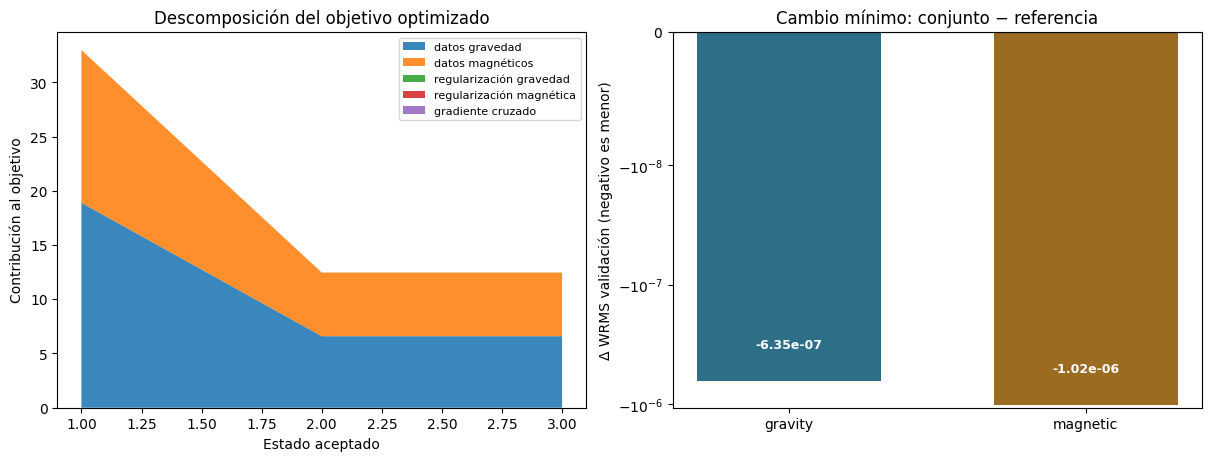

In [20]:
# Grafique la trayectoria aceptada y el pequeño cambio de validación por modalidad.
term_names = ["datos gravedad", "datos magnéticos", "regularización gravedad", "regularización magnética", "gradiente cruzado"]
iteration = np.arange(1, len(trace_terms) + 1)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), constrained_layout=True)
axes[0].stackplot(iteration, trace_terms.T, labels=term_names, alpha=0.88)
axes[0].set(title="Descomposición del objetivo optimizado", xlabel="Estado aceptado", ylabel="Contribución al objetivo")
axes[0].legend(loc="upper right", fontsize=8)
modalities = ("gravity", "magnetic")
positions = np.arange(2)
baseline_values = np.asarray([live_m11["selection"]["baseline_validation_wrms"][m] for m in modalities])
selected_values = np.asarray([live_m11["selection"]["validation_wrms"][m] for m in modalities])
delta = selected_values - baseline_values
axes[1].bar(positions, delta, color=["#2d6f87", "#9a6b20"], width=0.62)
axes[1].axhline(0.0, color="black", linewidth=0.8)
axes[1].set_yscale("symlog", linthresh=1e-8)
for position, value, color in zip(positions, delta, ("#2d6f87", "#9a6b20")):
    axes[1].text(position, value / 2, f"{value:.2e}", ha="center", va="center", color="white", fontsize=9, fontweight="bold")
axes[1].set(title="Cambio mínimo: conjunto − referencia", ylabel="Δ WRMS validación (negativo es menor)", xticks=positions, xticklabels=modalities)
plt.show()


### Interpretación de la figura final: predicciones directas iguales, conclusión acotada

Cada marcador compara predicciones gravimétricas o magnéticas del problema de desarrollo compilado con la ruta del objetivo público para el mismo modelo inicial y receptor. La diagonal y la discrepancia casi nula respaldan consistencia de implementación en este control de doce celdas y estas dos rutas. No comparan el solver inverso con una referencia, no explican la selección de acoplamiento en 24 casos ni muestran geología recuperada. El modelo es inicial, no estimado por optimización; las entradas son sintéticas y la elegibilidad de campo sigue falsa.
